# Notebook 08 — Behavioral Change Detection

A leakage-controlled study of historical customer behavior changes in the UK retail dataset. This notebook estimates continuous behavioral indicators and tests whether they improve short-horizon no-observed-purchase ranking. It does not label customers as churned, create live recommendations, or enable an alert policy.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

candidates = (Path.cwd(), *Path.cwd().parents)
PROJECT_ROOT = next(
    (path for path in candidates if (path / "data/processed/temporal/orders.csv").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not locate the OELP project root from the notebook working directory.")
sys.path.insert(0, str(PROJECT_ROOT))

from src.behavior_research import run_behavior_study

study = run_behavior_study(PROJECT_ROOT)
plt.close("all")
print(f"Project root: {PROJECT_ROOT}")
print(f"Evaluation: {study.evaluation['evaluation_version']} | TEST cutoff: {study.evaluation['test_cutoff_date']}")
print(f"Candidate F: {study.evaluation['candidate_f_status']}")

Project root: /home/runner/workspace
Evaluation: behavior-evaluation-v1 | TEST cutoff: 2010-09-10
Candidate F: not_fitted: no saved Purchase Clock vintage was available by any official TRAIN cutoff; the validation vintage was available only from 2010-06-30 and the test model was available by 2010-08-30


## 1. Research objectives and hypotheses

The target is **no observed purchase within the next 30, 60, or 90 days**. It is not permanent churn. H1 tests whether current elapsed time is unusual relative to a customer's own completed purchase gaps; H2 tests exposure-adjusted purchase-rate deterioration; H3 tests revenue-rate deterioration; H4 tests EWMA gap trajectory; H5 asks whether behavior adds information conditional on the existing Purchase Clock. H1–H4 are evaluated with validation-selected behavior-only model ablations. H5 is only partially assessed because no chronologically eligible Purchase Clock score exists at the official TRAIN cutoffs.

In [2]:
display(pd.DataFrame(study.evaluation["hypotheses"]))

,hypothesis,statement,status,evidence_summary
0,H1,Customers whose current gap is unusually long ...,supported_in_multiple_horizons,"P30 AP delta 0.003 (95% CI -0.001 to 0.007), P..."
1,H2,A decline in recent purchasing rate relative t...,inconclusive,"P30 AP delta 0.001 (95% CI -0.002 to 0.003), P..."
2,H3,A reduction in purchasing revenue rate may ind...,supported_in_multiple_horizons,"P30 AP delta -0.000 (95% CI -0.002 to 0.002), ..."
3,H4,The direction and persistence of behavior chan...,inconclusive,"P30 AP delta 0.000 (95% CI -0.000 to 0.000), P..."
4,H5,Behavior features add independent prospective ...,not_assessed_candidate_F_vintage_ineligible,Candidate E and the existing Purchase Clock ar...


## 2. Data source and analytical unit

The source is the project's existing invoice-level `orders.csv` and the saved temporal customer-feature snapshots. The unit is one customer at one official cutoff. Cancellations and administrative invoices are excluded by the reusable event-preparation function. Customer IDs remain identifiers only; no ID or future outcome enters the behavior-only predictor matrix.

In [3]:
display(pd.DataFrame([study.metadata["profiling"]]))
display(pd.DataFrame(study.metadata["official_split_cutoffs"]).T)

,order_rows,valid_purchase_events,customers_in_locked_test,distinct_cutoff_lambda_snapshots,event_preparation_seconds,validation_selection_seconds,locked_test_evaluation_seconds,total_seconds,feature_rows_scored_per_second,api_feature_snapshot_cached_per_process
0,19213,19213,3373,16,0.059016,2.654566,22.050236,25.271979,458.906655,True


,train,val,test
30,2010-06-01,2010-08-01,2010-09-10
60,2010-05-01,2010-07-01,2010-09-10
90,2010-03-01,2010-06-01,2010-09-10


## 3. Official cutoff and target-maturation schedule

TRAIN, VAL, and TEST dates are read from the project's official temporal split metadata and checked against each saved feature snapshot. The 30-day cohorts use June 1 / August 1 / September 10, 2010; the 60-day cohorts use May 1 / July 1 / September 10; the 90-day cohorts use March 1 / June 1 / September 10. Each TEST outcome is constructed only after all feature/model selection is frozen, and its full target horizon must be observable by the dataset end.

In [4]:
assert study.metadata["test_cutoff"] == "2010-09-10"
assert study.metadata["test_outcomes_used_for_selection_or_training"] is False
display(pd.DataFrame.from_dict(study.metadata["official_split_cutoffs"], orient="index"))

,train,val,test
30,2010-06-01,2010-08-01,2010-09-10
60,2010-05-01,2010-07-01,2010-09-10
90,2010-03-01,2010-06-01,2010-09-10


## 4. Feature engineering and definitions

The implementation lives in `src/behavior_monitor.py` and is reused by the API. It computes: (1) current elapsed gap versus the customer's pre-cutoff median gap, scaled by robust MAD; (2) recent `[t−30,t)` versus reference `[t−120,t−30)` order rates with observed exposure and a declared prior; (3) gross-revenue rates without adding a fake spending pseudocount; and (4) recent/reference EWMA gaps from completed intervals only. A shortened exposure is used when a customer's first observed purchase occurs inside a window. Features with insufficient history stay unavailable instead of receiving fabricated values.

In [5]:
display(pd.DataFrame([{
    "feature_version": study.metadata["feature_version"],
    "policy_version": study.metadata["policy_version"],
    "serving_ewma_lambda": study.metadata["serving_ewma_lambda_selected_on_validation"],
    "config": study.metadata["config"],
}]))

,feature_version,policy_version,serving_ewma_lambda,config
0,behavior-monitor-v1,behavior-continuous-v1,0.6,"{'recent_window_days': 30, 'reference_window_d..."


## 5. Leakage controls and data-quality checks

Behavior snapshots use strictly pre-cutoff events, half-open non-overlapping rate windows, and completed purchase gaps only. The reusable module's tests cover cutoff invariance, same-timestamp invoices, cancellations, exposure shortening, history sufficiency, and continuous-only scores. The research runner reads feature columns without target columns, constructs TRAIN/VAL outcomes using the existing temporal target function, selects on VAL, and only then constructs TEST labels. No random split, full-year customer segmentation, or TEST tuning is used.

In [6]:
assert study.metadata["test_outcomes_used_for_selection_or_training"] is False
assert study.metadata["alert_policy_available"] is False
assert study.metadata["purchase_clock_vintage_audit"]["eligible_for_candidate_f_training"] is False
print("Cutoff and vintage assertions passed; Candidate F was not fitted.")

Cutoff and vintage assertions passed; Candidate F was not fitted.


## 6. Profiling and operational footprint

The measurements below were captured during the executed run. API feature computation is cached per process so filters and pages reuse a single cutoff snapshot. No per-customer model artifact or categorical alert policy is saved.

In [7]:
display(pd.DataFrame([study.metadata["profiling"]]).T.rename(columns={0: "measured value"}))

,measured value
order_rows,19213
valid_purchase_events,19213
customers_in_locked_test,3373
distinct_cutoff_lambda_snapshots,16
event_preparation_seconds,0.059016
validation_selection_seconds,2.654566
locked_test_evaluation_seconds,22.050236
total_seconds,25.271979
feature_rows_scored_per_second,458.906655
api_feature_snapshot_cached_per_process,True


## 7. Validation-only model selection

Candidate E is a behavior-only L2 logistic model. EWMA λ is selected from the prespecified `{0.2, 0.4, 0.6}` candidates, and regularization C from `{0.1, 1, 10}`. Training uses TRAIN only; the validation selection criterion is average precision, with Brier score as the tie-breaker. The selected model is not refit on TEST or tuned after inspecting TEST.

In [8]:
display(study.lambda_selection.sort_values(["horizon_days", "ewma_lambda"]).reset_index(drop=True))
display(study.selection)

,horizon_days,ewma_lambda,regularization_c,validation_average_precision,validation_brier_score,validation_customers
0,30,0.2,1.0,0.867103,0.156611,3159
1,30,0.4,0.1,0.868602,0.156378,3159
2,30,0.6,0.1,0.869307,0.156083,3159
3,60,0.2,0.1,0.763747,0.206460,2973
4,60,0.4,0.1,0.766104,0.205758,2973
5,60,0.6,0.1,0.766111,0.205755,2973
6,90,0.2,10.0,0.626453,0.256973,2703
7,90,0.4,10.0,0.627127,0.256977,2703
8,90,0.6,10.0,0.627185,0.256976,2703


,horizon_days,ewma_lambda,regularization_c,validation_average_precision,validation_brier_score,validation_customers,active_features
0,30,0.6,0.1,0.869307,0.156083,3159,"[gap_deviation_score, purchase_rate_ratio, pur..."
1,60,0.6,0.1,0.766111,0.205755,2973,"[gap_deviation_score, purchase_rate_ratio, pur..."
2,90,0.6,10.0,0.627185,0.256976,2703,"[gap_deviation_score, purchase_rate_ratio, pur..."


## 8. Locked TEST baseline comparison

A is a TRAIN-derived global inactivity indicator; B is recency ranking; C is the existing personalized delay ratio; D is the saved Purchase Clock; E is behavior-only. Ranking metrics include ROC-AUC, average precision, and precision/recall at a fixed top-decile customer budget. Probability metrics are reported only for D and E. The validation-selected score threshold is shown only as a frozen evaluation reference; it does not create customer-facing alert categories.

In [9]:
comparison_columns = [
    "horizon_days", "model", "n_customers", "roc_auc", "average_precision",
    "precision_at_budget", "recall_at_budget", "brier_score", "log_loss",
    "alert_coverage", "false_alert_rate", "threshold",
    "frozen_threshold_alert_coverage", "frozen_threshold_false_alert_rate", "status",
]
display(study.comparison.loc[:, comparison_columns].sort_values(["horizon_days", "model"]))

,horizon_days,model,n_customers,roc_auc,average_precision,precision_at_budget,recall_at_budget,brier_score,log_loss,alert_coverage,false_alert_rate,threshold,frozen_threshold_alert_coverage,frozen_threshold_false_alert_rate,status
4,30,Behavior features only,3373,0.674660,0.814582,0.807692,0.112299,0.182387,0.552924,0.100208,0.069002,0.850824,0.325230,0.185775,evaluated_on_locked_TEST
7,30,Candidate E without frequency_change,3373,0.670612,0.813949,0.810651,0.112711,0.181895,0.548630,0.100208,0.067941,NaN,NaN,NaN,evaluated_on_locked_TEST
6,30,Candidate E without personalized_gap,3373,0.661732,0.811713,0.825444,0.114768,0.187631,0.560085,0.100208,0.062633,NaN,NaN,NaN,evaluated_on_locked_TEST
8,30,Candidate E without spending_change,3373,0.677944,0.814922,0.822485,0.114356,0.181663,0.550718,0.100208,0.063694,NaN,NaN,NaN,evaluated_on_locked_TEST
9,30,Candidate E without trajectory_change,3373,0.673891,0.814465,0.810651,0.112711,0.183009,0.553547,0.100208,0.067941,NaN,NaN,NaN,evaluated_on_locked_TEST
0,30,Global inactivity indicator,3373,0.588287,0.762952,0.872781,0.121349,NaN,NaN,0.100208,0.045648,1.000000,0.262081,0.134820,evaluated_on_locked_TEST
3,30,Personalized Purchase Clock,3373,0.720882,0.852349,0.893491,0.124229,0.178534,0.540297,0.100208,0.038217,NaN,NaN,NaN,evaluated_on_locked_TEST
2,30,Personalized delay ratio,3373,0.638047,0.808799,0.869822,0.120938,NaN,NaN,0.100208,0.046709,8.876222,0.147940,0.067941,evaluated_on_locked_TEST
5,30,Purchase Clock + behavior,3373,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,not_fitted: no saved Purchase Clock vintage wa...
1,30,Recency-only ranking,3373,0.646952,0.816169,0.884615,0.122995,NaN,NaN,0.100208,0.041401,183.000000,0.155944,0.074310,evaluated_on_locked_TEST


## 9. Paired customer-level uncertainty

Differences are bootstrapped with customer IDs as the sampling clusters and the same sampled customers applied to both score series. TEST contains one row per customer at each horizon. Positive AP differences favor Candidate E; for Brier score, negative differences favor Candidate E. The intervals quantify sampling uncertainty on this historical cohort, not uncertainty about future populations.

In [10]:
display(pd.DataFrame(study.evaluation["bootstrap_comparisons"]))

,horizon_days,comparison,metric,difference_first_minus_second,confidence_interval_95_lower,confidence_interval_95_upper,valid_resamples,requested_resamples,customer_clusters,resampling_unit
0,30,Candidate E vs Personalized Purchase Clock,average_precision,-0.037767,-0.048326,-0.026521,500,500,3373,Customer ID; paired across both score series
1,30,Candidate E vs Personalized Purchase Clock,brier,0.003853,0.000098,0.007813,500,500,3373,Customer ID; paired across both score series
2,30,Candidate E vs E without personalized_gap,average_precision,0.002869,-0.001339,0.006928,500,500,3373,Customer ID; paired across both score series
3,30,Candidate E vs E without frequency_change,average_precision,0.000633,-0.001852,0.003080,500,500,3373,Customer ID; paired across both score series
4,30,Candidate E vs E without spending_change,average_precision,-0.000340,-0.002414,0.001530,500,500,3373,Customer ID; paired across both score series
5,30,Candidate E vs E without trajectory_change,average_precision,0.000117,-0.000166,0.000404,500,500,3373,Customer ID; paired across both score series
6,60,Candidate E vs Personalized Purchase Clock,average_precision,-0.046004,-0.063584,-0.029169,500,500,3373,Customer ID; paired across both score series
7,60,Candidate E vs Personalized Purchase Clock,brier,0.005988,0.001302,0.011046,500,500,3373,Customer ID; paired across both score series
8,60,Candidate E vs E without personalized_gap,average_precision,0.007631,0.003658,0.011766,500,500,3373,Customer ID; paired across both score series
9,60,Candidate E vs E without frequency_change,average_precision,0.006697,-0.001691,0.014032,500,500,3373,Customer ID; paired across both score series


## 10. H1–H5 evidence

H1–H4 compare the full behavior-only model with a version that omits one prespecified feature family; remaining model complexity is selected on VAL. H5's separate-model comparison is not a test of conditional incremental value. Candidate F would require a Purchase Clock probability available at each TRAIN cutoff; the saved vintages do not meet that timing requirement.

In [11]:
display(pd.DataFrame(study.evaluation["hypotheses"]))
display(study.ablations)

,hypothesis,statement,status,evidence_summary
0,H1,Customers whose current gap is unusually long ...,supported_in_multiple_horizons,"P30 AP delta 0.003 (95% CI -0.001 to 0.007), P..."
1,H2,A decline in recent purchasing rate relative t...,inconclusive,"P30 AP delta 0.001 (95% CI -0.002 to 0.003), P..."
2,H3,A reduction in purchasing revenue rate may ind...,supported_in_multiple_horizons,"P30 AP delta -0.000 (95% CI -0.002 to 0.002), ..."
3,H4,The direction and persistence of behavior chan...,inconclusive,"P30 AP delta 0.000 (95% CI -0.000 to 0.000), P..."
4,H5,Behavior features add independent prospective ...,not_assessed_candidate_F_vintage_ineligible,Candidate E and the existing Purchase Clock ar...


,horizon_days,comparison,metric,difference_first_minus_second,confidence_interval_95_lower,confidence_interval_95_upper
0,30,Candidate E vs E without personalized_gap,average_precision,0.002869,-0.001339,0.006928
1,30,Candidate E vs E without frequency_change,average_precision,0.000633,-0.001852,0.003080
2,30,Candidate E vs E without spending_change,average_precision,-0.000340,-0.002414,0.001530
3,30,Candidate E vs E without trajectory_change,average_precision,0.000117,-0.000166,0.000404
4,60,Candidate E vs E without personalized_gap,average_precision,0.007631,0.003658,0.011766
5,60,Candidate E vs E without frequency_change,average_precision,0.006697,-0.001691,0.014032
6,60,Candidate E vs E without spending_change,average_precision,0.003923,0.002443,0.005344
7,60,Candidate E vs E without trajectory_change,average_precision,-0.000210,-0.000730,0.000267
8,90,Candidate E vs E without personalized_gap,average_precision,0.006703,0.003635,0.009742
9,90,Candidate E vs E without frequency_change,average_precision,-0.000145,-0.017500,0.015404


## 11. Subgroups, sensitivity, and error review

Performance is broken out by the predeclared history-sufficiency classes and saved historical segments. One-class subgroup outcomes are marked as unavailable for ranking metrics. The feature-family ablations provide a sensitivity check on the contribution of personalized gap, purchase-rate, revenue-rate, and EWMA information. No test result is used to revise the feature or threshold policy.

In [12]:
display(study.subgroups.sort_values(["horizon_days", "group_type", "group", "model"]))

,horizon_days,model,group_type,group,n_customers,nonpurchase_rate,roc_auc,average_precision,status
3,30,Behavior features only,historical_segment,Lapsed / At-Risk,2088,0.825670,0.540248,0.842186,evaluated
8,30,Personalized Purchase Clock,historical_segment,Lapsed / At-Risk,2088,0.825670,0.620962,0.880275,evaluated
4,30,Behavior features only,historical_segment,Recent / Active,1285,0.550195,0.625675,0.639464,evaluated
9,30,Personalized Purchase Clock,historical_segment,Recent / Active,1285,0.550195,0.667539,0.658389,evaluated
0,30,Behavior features only,history_sufficiency,insufficient,313,0.798722,0.500000,0.798722,evaluated
5,30,Personalized Purchase Clock,history_sufficiency,insufficient,313,0.798722,0.635238,0.866568,evaluated
1,30,Behavior features only,history_sufficiency,limited,2335,0.792719,0.573416,0.829113,evaluated
6,30,Personalized Purchase Clock,history_sufficiency,limited,2335,0.792719,0.653943,0.870340,evaluated
2,30,Behavior features only,history_sufficiency,sufficient,725,0.455172,0.561795,0.512017,evaluated
7,30,Personalized Purchase Clock,history_sufficiency,sufficient,725,0.455172,0.662232,0.573598,evaluated


## 12. Customer-level descriptive examples

Examples are selected from the locked-cutoff feature values alone, not by whether a customer did or did not purchase afterward. The chart displays only pre-cutoff 30-day windows. These are illustrative historical trajectories, not explanations of an intervention or a prediction of a customer's future.

,customer_id,cutoff_date,selection_reason,history_sufficiency,gap_deviation_score
0,15413,2010-09-10,largest observed gap deviation with sufficient...,sufficient,228.439583
1,13085,2010-09-10,largest observed gap deviation with sufficient...,sufficient,223.445833
2,15359,2010-09-10,largest observed gap deviation with sufficient...,sufficient,206.550000


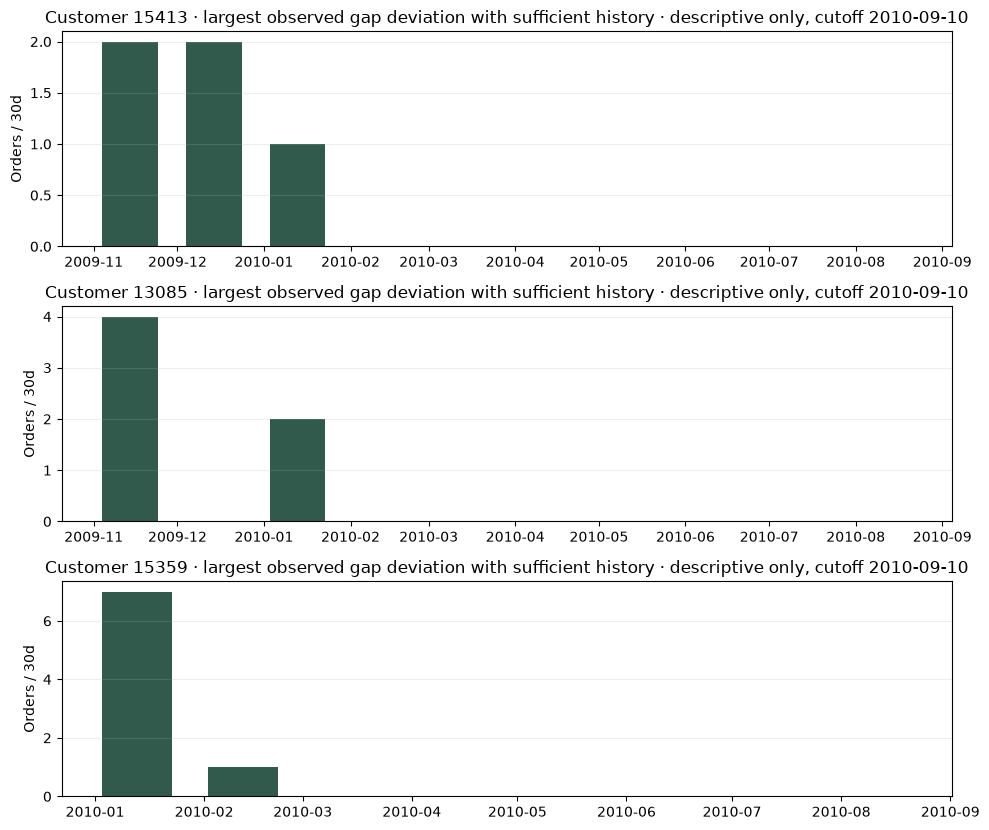

In [13]:
case_columns = ["customer_id", "cutoff_date", "selection_reason", "history_sufficiency", "gap_deviation_score"]
display(study.case_studies.loc[:, case_columns])
display(study.figures["customer_trajectories"])

## 13. Cohort and model visual review

Distributions are shown with their actual observed support; missing values remain missing. The top-decile chart is a fixed-budget ranking comparison and should not be interpreted as a production alert threshold.

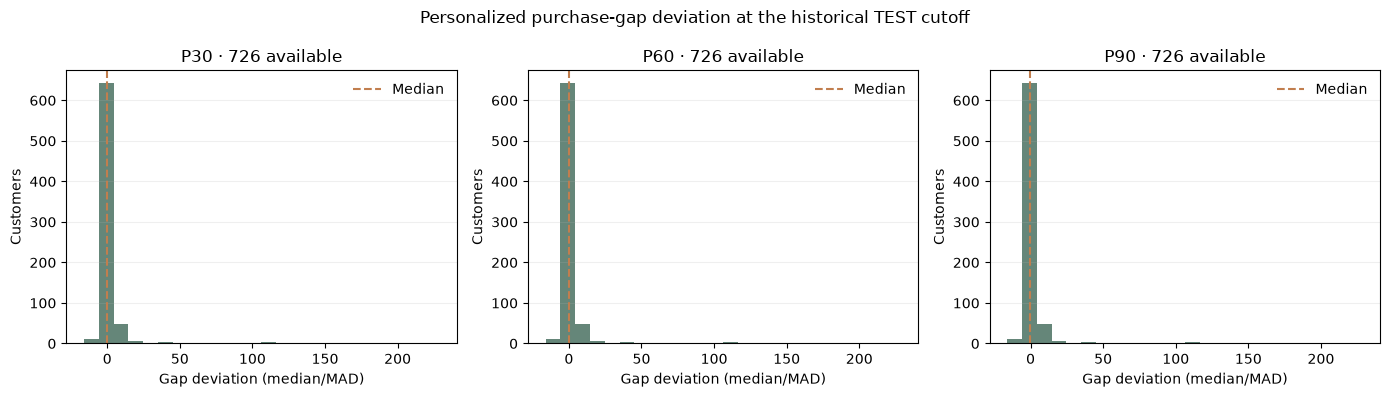

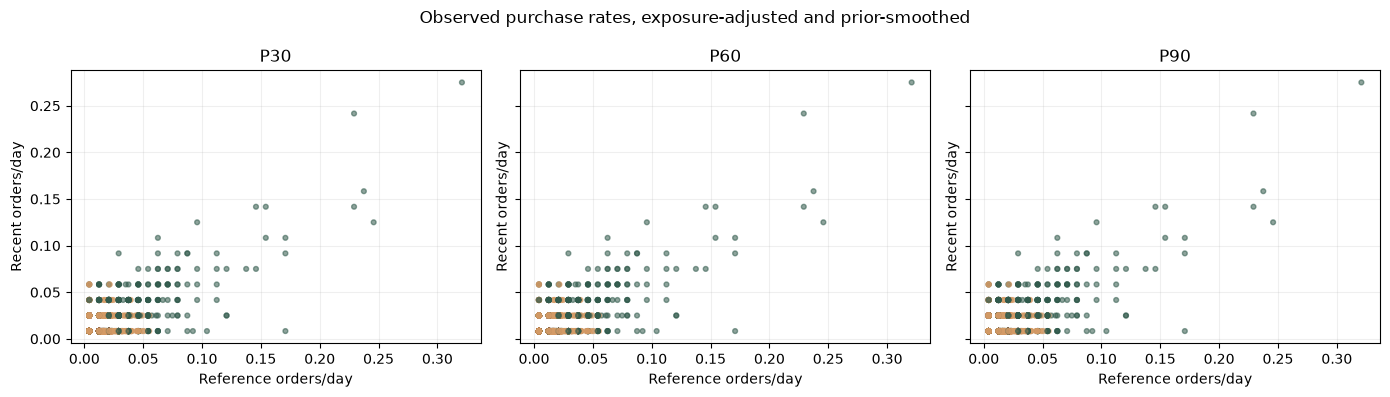

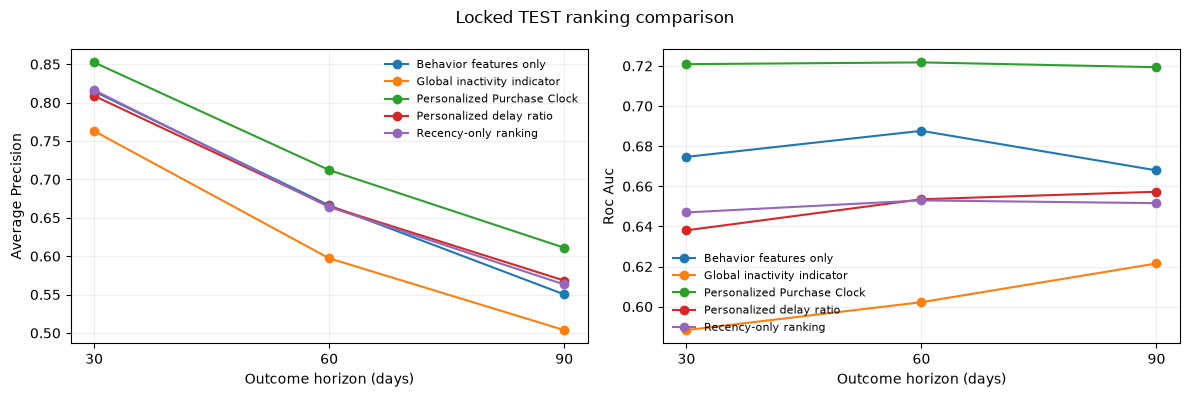

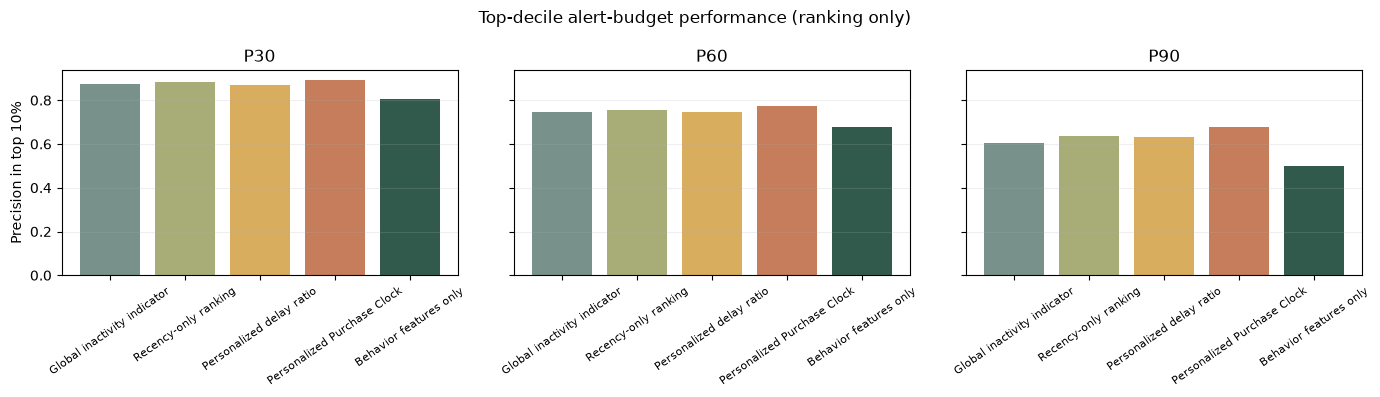

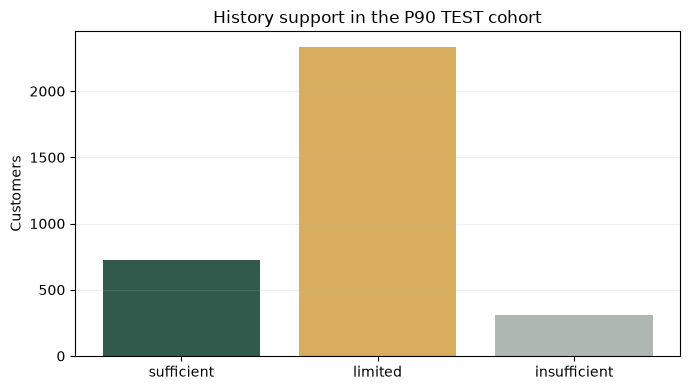

In [14]:
for figure_name in ("gap_deviation", "purchase_rates", "baseline_comparison", "alert_budget", "history_sufficiency"):
    display(study.figures[figure_name])

## 14. Saved model metadata and policy boundary

The run saves versioned configuration metadata and measured evaluation JSON. It does not save a deployable logistic model, a categorical threshold policy, or a fake Candidate F score. The reusable API serves continuous historical indicators and the saved evaluation results; no alert categories are enabled.

In [15]:
display(pd.DataFrame([{
    "feature_version": study.metadata["feature_version"],
    "policy_version": study.metadata["policy_version"],
    "candidate_f_status": study.metadata["candidate_f_status"],
    "alert_policy_available": study.metadata["alert_policy_available"],
    "saved_metadata": str(PROJECT_ROOT / "models/behavior_monitor/metadata.json"),
    "saved_evaluation": str(PROJECT_ROOT / "data/metrics/behavior_monitor_evaluation.json"),
    "saved_profiling": str(PROJECT_ROOT / "data/metrics/behavior_monitor_profiling.json"),
}]))

,feature_version,policy_version,candidate_f_status,alert_policy_available,saved_metadata,saved_evaluation,saved_profiling
0,behavior-monitor-v1,behavior-continuous-v1,not_fitted: no saved Purchase Clock vintage wa...,False,/home/runner/workspace/models/behavior_monitor...,/home/runner/workspace/data/metrics/behavior_m...,/home/runner/workspace/data/metrics/behavior_m...


## 15. Limitations and conclusion

The dataset is a sparse historical retail cohort. No observed purchase is horizon-specific and does not prove churn. Repeated customers across cutoffs limit naive independence assumptions; the held-out bootstrap clusters by customer. Revenue can be zero or irregular, so the rate is unavailable where reference support is absent. H5 remains unresolved: without a chronologically eligible Purchase Clock score at TRAIN, no conditional Candidate F can be evaluated. Results describe backtest ranking and calibration only; they do not establish causal intervention value or authorize operational alerts.

In [16]:
print("Notebook 08 completed.")
print(f"Locked TEST cutoff: {study.evaluation['test_cutoff_date']}")
print(f"Candidate F: {study.evaluation['candidate_f_status']}")
print("No alert policy was enabled.")
display(pd.DataFrame(study.evaluation["limitations"], columns=["limitation"]))

Notebook 08 completed.
Locked TEST cutoff: 2010-09-10
Candidate F: not_fitted: no saved Purchase Clock vintage was available by any official TRAIN cutoff; the validation vintage was available only from 2010-06-30 and the test model was available by 2010-08-30
No alert policy was enabled.


,limitation
0,Outcome means no observed purchase within the ...
1,The Year 1 UK retail cohort is sparse and the ...
2,Candidate F was not fitted because the saved P...
3,Candidate E versus the Purchase Clock compares...
4,The top-10% ranking comparison is an evaluatio...
5,Customer-level bootstrap intervals assume the ...
6,Some recent/reference revenue and EWMA feature...
